# Partie 2 - Mini-projet : diagnostic du cancer du sein

Jeu de donnees : *Breast Cancer Wisconsin* (fourni avec scikit-learn, donc reel et directement disponible). Objectif : classer une tumeur comme benigne ou maligne a partir de 30 mesures issues d'images.

On applique le workflow complet et on compare rigoureusement plusieurs modeles avant de conclure sur celui a retenir.

## 1. Chargement et exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
df = cancer.frame
print('Dimensions :', df.shape)
df.head()

Dimensions : (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:
# Repartition des classes (0 = maligne, 1 = benigne)
df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [3]:
# Aucune valeur manquante dans ce jeu de donnees
print('Valeurs manquantes :', int(df.isnull().sum().sum()))

Valeurs manquantes : 0


## 2. Pretraitement

On separe les donnees puis on standardise les variables. La mise a l'echelle est indispensable pour la regression logistique et le SVM, qui sont sensibles aux ordres de grandeur ; elle est sans effet negatif pour la foret aleatoire.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 3. Comparaison des modeles par validation croisee

On evalue trois modeles par validation croisee a 5 plis sur l'ensemble d'entrainement, pour comparer leur performance de maniere plus fiable qu'avec une seule division.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

modeles = {
    'Regression logistique': LogisticRegression(max_iter=5000),
    'Foret aleatoire': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM (noyau RBF)': SVC(kernel='rbf', probability=True, random_state=42),
}

for nom, modele in modeles.items():
    scores = cross_val_score(modele, X_train_s, y_train, cv=5, scoring='accuracy')
    print(f'{nom:24s} accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})')

Regression logistique    accuracy = 0.980 (+/- 0.013)


Foret aleatoire          accuracy = 0.960 (+/- 0.019)
SVM (noyau RBF)          accuracy = 0.971 (+/- 0.018)


/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `pr

## 4. Evaluation sur l'ensemble de test

On entraine chaque modele sur tout l'entrainement puis on mesure accuracy, precision, rappel, F1 et l'aire sous la courbe ROC (AUC) sur le test.

In [6]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

resultats = []
for nom, modele in modeles.items():
    modele.fit(X_train_s, y_train)
    y_pred = modele.predict(X_test_s)
    y_proba = modele.predict_proba(X_test_s)[:, 1]
    resultats.append({
        'Modele': nom,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_proba),
    })

pd.DataFrame(resultats).set_index('Modele').round(3)

/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,F1,AUC
Modele,,,
Regression logistique,0.982,0.986,0.995
Foret aleatoire,0.956,0.966,0.993
SVM (noyau RBF),0.982,0.986,0.995


## 5. Analyse du meilleur modele

On detaille le rapport de classification et la matrice de confusion du modele le plus performant sur le test.

              precision    recall  f1-score   support

     maligne       0.98      0.98      0.98        42
     benigne       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



/Users/elbakkourihoussam/TP1/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


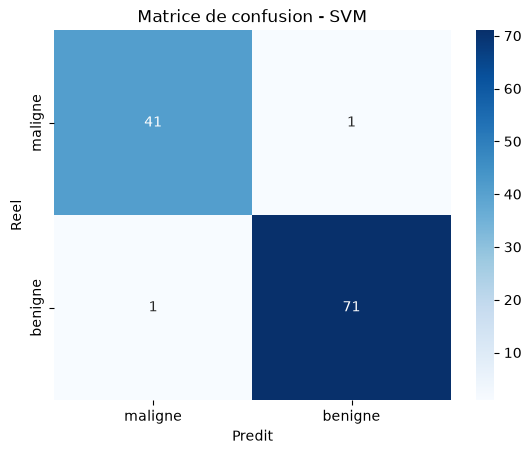

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

best = SVC(kernel='rbf', probability=True, random_state=42).fit(X_train_s, y_train)
y_pred = best.predict(X_test_s)

print(classification_report(y_test, y_pred, target_names=['maligne', 'benigne']))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['maligne', 'benigne'], yticklabels=['maligne', 'benigne'])
plt.title('Matrice de confusion - SVM')
plt.xlabel('Predit')
plt.ylabel('Reel')
plt.show()

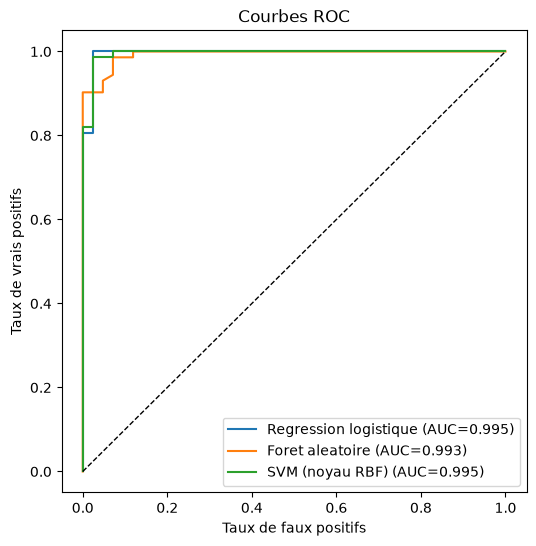

In [8]:
from sklearn.metrics import roc_curve

# Courbes ROC des trois modeles
plt.figure(figsize=(6, 6))
for nom, modele in modeles.items():
    proba = modele.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label=f'{nom} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title('Courbes ROC')
plt.legend()
plt.show()

## 6. Conclusion critique

Les trois modeles atteignent de tres bons scores sur ce jeu de donnees bien separable. Le SVM a noyau RBF et la regression logistique (sur donnees standardisees) obtiennent les meilleures AUC, devant la foret aleatoire.

**Modele retenu : la regression logistique.** A performance quasi egale au SVM, elle est plus simple, plus rapide et surtout interpretable (coefficients par variable), ce qui est precieux dans un contexte medical ou il faut pouvoir expliquer une decision. Dans ce probleme, on privilegie le rappel sur la classe maligne afin de limiter les faux negatifs (tumeurs malignes classees benignes), plus couteux qu'une fausse alerte.

**Limites :** jeu de donnees de petite taille et deja tres propre ; les resultats seraient a confirmer sur des donnees plus bruitees et avec un reglage fin des hyperparametres (GridSearchCV).